<a href="https://colab.research.google.com/github/gavuthamaankindle-ux/2d-subway-surfer/blob/main/AiMlassignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import urllib.request
import zipfile
import os

print("Downloading NASA C-MAPSS dataset...")
url = "https://data.nasa.gov/docs/legacy/CMAPSSData.zip"
urllib.request.urlretrieve(url, "CMAPSSData.zip")

with zipfile.ZipFile("CMAPSSData.zip", "r") as zip_ref:
    zip_ref.extractall("cmapss_data")

print("Dataset successfully downloaded and extracted!")

Dataset successfully downloaded and extracted!


In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Define column names for C-MAPSS data files
columns = ['unit_nr', 'time_cycle', 'setting_1', 'setting_2', 'setting_3'] + [f's_{i}' for i in range(1, 22)]

# Load training data (FD001 subset: single operating condition, single failure mode)
train_df = pd.read_csv('cmapss_data/train_FD001.txt', sep='\s+', header=None)
train_df = train_df.iloc[:, :26]  # Drop trailing empty columns
train_df.columns = columns

# Calculate True RUL per engine and cap at 125 cycles (piecewise linear target)
rul = train_df.groupby('unit_nr')['time_cycle'].max().reset_index()
rul.columns = ['unit_nr', 'max_cycle']
train_df = train_df.merge(rul, on='unit_nr', how='left')
train_df['RUL'] = train_df['max_cycle'] - train_df['time_cycle']
train_df['RUL'] = train_df['RUL'].clip(upper=125)
train_df.drop(columns=['max_cycle'], inplace=True)

# Drop sensors with zero variance (flat lines that carry no degradation signal)
drop_sensors = ['s_1', 's_5', 's_6', 's_10', 's_16', 's_18', 's_19']
feature_cols = [col for col in columns[5:] if col not in drop_sensors]

# Normalize sensor features
scaler = StandardScaler()
train_df[feature_cols] = scaler.fit_transform(train_df[feature_cols])

# Generate sliding time windows (e.g., lookback of 30 cycles)
def gen_sequences(df, feature_cols, seq_length=30):
    X, y = [], []
    for engine_id, group in df.groupby('unit_nr'):
        if len(group) >= seq_length:
            mat = group[feature_cols].values
            target = group['RUL'].values
            for i in range(len(group) - seq_length):
                X.append(mat[i:(i + seq_length), :])
                y.append(target[i + seq_length])
    return np.array(X), np.array(y)

seq_length = 30
X_train, y_train = gen_sequences(train_df, feature_cols, seq_length)

print(f"Preprocessing Complete!")
print(f"X_train shape (Samples, Time Steps, Features): {X_train.shape}")
print(f"y_train shape (Remaining Useful Life): {y_train.shape}")

<>:9: SyntaxWarning: invalid escape sequence '\s'
<>:9: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_652/2323253506.py:9: SyntaxWarning: invalid escape sequence '\s'
  train_df = pd.read_csv('cmapss_data/train_FD001.txt', sep='\s+', header=None)


Preprocessing Complete!
X_train shape (Samples, Time Steps, Features): (17631, 30, 14)
y_train shape (Remaining Useful Life): (17631,)


In [3]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Automatically use Colab's GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using compute device: {device}")

class RUL_LSTM(nn.Module):
    def __init__(self, input_dim):
        super(RUL_LSTM, self).__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=64,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )
        self.fc1 = nn.Linear(64, 32)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]  # Extract output from the final time step of the window
        out = self.fc1(out)
        out = self.relu(out)
        out = self.fc2(out)
        return out

input_dim = X_train.shape[2]
model = RUL_LSTM(input_dim).to(device)
print(model)

Using compute device: cuda
RUL_LSTM(
  (lstm): LSTM(14, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)


In [4]:
# Convert numpy arrays to PyTorch tensors
X_tensor = torch.tensor(X_train, dtype=torch.float32)
y_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)

dataset = TensorDataset(X_tensor, y_tensor)
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 20
model.train()

print("Starting model training...")
for epoch in range(epochs):
    epoch_loss = 0
    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    print(f"Epoch [{epoch+1}/{epochs}], Loss (MSE): {epoch_loss/len(dataloader):.4f}")

print("Training finished successfully!")

Starting model training...
Epoch [1/20], Loss (MSE): 4320.1212
Epoch [2/20], Loss (MSE): 460.1047
Epoch [3/20], Loss (MSE): 221.2619
Epoch [4/20], Loss (MSE): 176.8721
Epoch [5/20], Loss (MSE): 161.5160
Epoch [6/20], Loss (MSE): 150.4545
Epoch [7/20], Loss (MSE): 141.7078
Epoch [8/20], Loss (MSE): 132.9819
Epoch [9/20], Loss (MSE): 124.6173
Epoch [10/20], Loss (MSE): 116.7940
Epoch [11/20], Loss (MSE): 107.5645
Epoch [12/20], Loss (MSE): 103.3069
Epoch [13/20], Loss (MSE): 95.7091
Epoch [14/20], Loss (MSE): 90.8096
Epoch [15/20], Loss (MSE): 83.1486
Epoch [16/20], Loss (MSE): 76.7165
Epoch [17/20], Loss (MSE): 73.1216
Epoch [18/20], Loss (MSE): 68.6730
Epoch [19/20], Loss (MSE): 62.5233
Epoch [20/20], Loss (MSE): 58.0538
Training finished successfully!


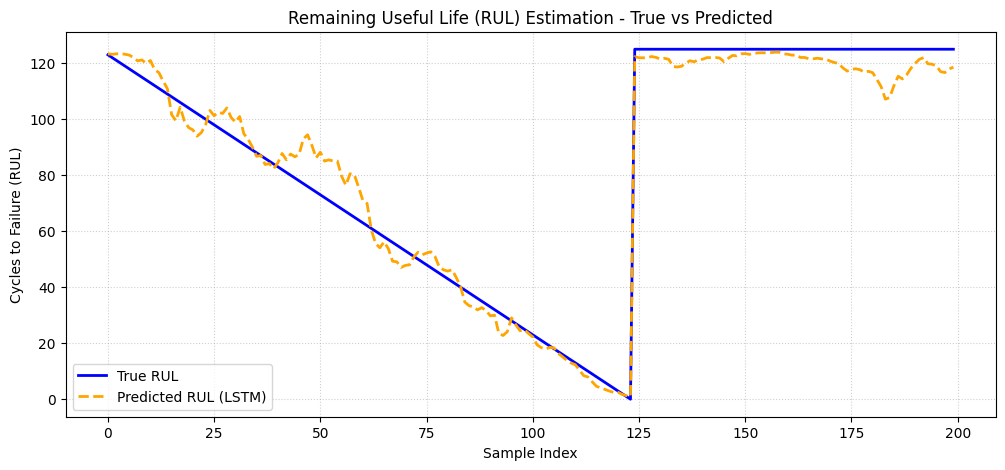

In [5]:
import matplotlib.pyplot as plt

model.eval()
with torch.no_grad():
    # Pick a sample slice of sequences to evaluate
    sample_X = torch.tensor(X_train[1000:1200], dtype=torch.float32).to(device)
    sample_preds = model(sample_X).cpu().numpy().flatten()
    sample_trues = y_train[1000:1200]

# Plot True vs Predicted curves
plt.figure(figsize=(12, 5))
plt.plot(sample_trues, label="True RUL", color="blue", linewidth=2)
plt.plot(sample_preds, label="Predicted RUL (LSTM)", color="orange", linestyle="--", linewidth=2)
plt.title("Remaining Useful Life (RUL) Estimation - True vs Predicted")
plt.xlabel("Sample Index")
plt.ylabel("Cycles to Failure (RUL)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()